In [15]:
!pip install torch torchvision torchaudio
!pip install numpy matplotlib seaborn scikit-learn tqdm



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize


In [17]:
# ---------------- CONFIG ----------------
BATCH_SIZE = 32
IMG_SIZE = 224
EPOCHS = 20
LEARNING_RATE = 1e-4
RANDOM_STATE = 42

TRAIN_VAL_DIR = r"C:\Users\agarw\OneDrive\Desktop\KERATOCONUS\Train_Validation sets"
TEST_DIR = r"C:\Users\agarw\OneDrive\Desktop\KERATOCONUS\Independent Test Set"

CLASSES = ['Normal', 'Suspect', 'Keratoconus']
NUM_CLASSES = len(CLASSES)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)


Using device: cpu


In [18]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])


In [19]:
full_dataset = datasets.ImageFolder(TRAIN_VAL_DIR, transform=train_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=val_test_transform)

print("Classes:", full_dataset.classes)
print("Total Train+Val:", len(full_dataset))
print("Total Test:", len(test_dataset))


Classes: ['Keratoconus', 'Normal', 'Suspect']
Total Train+Val: 2961
Total Test: 1050


In [20]:
targets = [sample[1] for sample in full_dataset.samples]
indices = list(range(len(full_dataset)))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=targets,
    random_state=RANDOM_STATE
)

train_dataset = Subset(full_dataset, train_idx)
val_dataset = Subset(
    datasets.ImageFolder(TRAIN_VAL_DIR, transform=val_test_transform),
    val_idx
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))


Train: 2368
Validation: 593


In [21]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


In [22]:
model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

# Freeze convolution layers
for param in model.features.parameters():
    param.requires_grad = False

# Replace final classifier layer
model.classifier[6] = nn.Linear(4096, NUM_CLASSES)

model = model.to(DEVICE)
print(model)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

best_val_acc = 0.0

for epoch in range(EPOCHS):
    model.train()
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total
    print(f"Epoch {epoch+1}: Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "vgg16_best.pth")
        print("Saved best model")


Epoch 1/20: 100%|██████████| 74/74 [06:07<00:00,  4.96s/it]


Epoch 1: Train Acc=0.5705, Val Acc=0.5953
Saved best model


Epoch 2/20: 100%|██████████| 74/74 [05:52<00:00,  4.76s/it]


Epoch 2: Train Acc=0.6482, Val Acc=0.6779
Saved best model


Epoch 3/20: 100%|██████████| 74/74 [05:50<00:00,  4.74s/it]


Epoch 3: Train Acc=0.6584, Val Acc=0.6712


... (30 outputs left out)

Epoch 19/20: 100%|██████████| 74/74 [03:55<00:00,  3.18s/it]


Epoch 19: Train Acc=0.7766, Val Acc=0.7218


Epoch 20/20: 100%|██████████| 74/74 [03:51<00:00,  3.13s/it]


Epoch 20: Train Acc=0.7648, Val Acc=0.7218


In [25]:
model.load_state_dict(torch.load("vgg16_best.pth"))
model.eval()

y_true = []
y_pred = []
y_scores = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

        y_scores.extend(probs.cpu().numpy())
        y_true.extend(labels.numpy())
        y_pred.extend(torch.argmax(probs, dim=1).cpu().numpy())

y_scores = np.array(y_scores)

test_acc = accuracy_score(y_true, y_pred)
print("Test Accuracy:", test_acc)


Test Accuracy: 0.5952380952380952


In [26]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASSES))



Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.64      0.76       350
     Suspect       0.61      0.39      0.47       350
 Keratoconus       0.45      0.76      0.56       350

    accuracy                           0.60      1050
   macro avg       0.67      0.60      0.60      1050
weighted avg       0.67      0.60      0.60      1050



In [29]:
# Compute per-class and aggregate F1 scores
try:
    from sklearn.metrics import f1_score

    f1_scores = f1_score(y_true, y_pred, average=None)
    for cls, score in zip(CLASSES, f1_scores):
        print(f"{cls}: F1 = {score:.4f}")

    print("\nMacro F1:", f1_score(y_true, y_pred, average='macro'))
    print("Micro F1:", f1_score(y_true, y_pred, average='micro'))
except NameError:
    print("`y_true` or `y_pred` not found — run the evaluation cell first.")


Normal: F1 = 0.7637
Suspect: F1 = 0.4739
Keratoconus: F1 = 0.5648

Macro F1: 0.6007740215323302
Micro F1: 0.5952380952380952


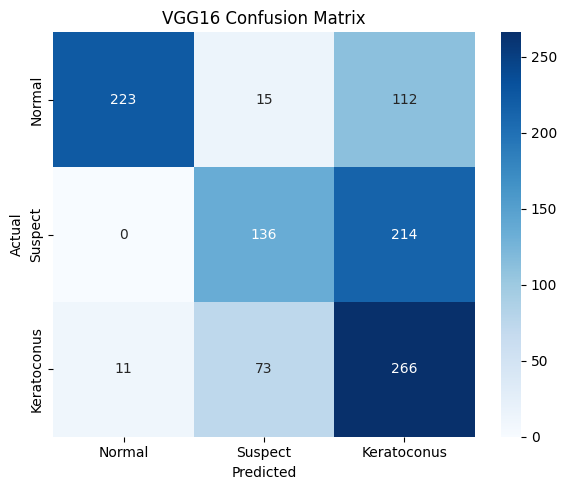

In [27]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=CLASSES,
            yticklabels=CLASSES,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("VGG16 Confusion Matrix")
plt.tight_layout()
plt.show()


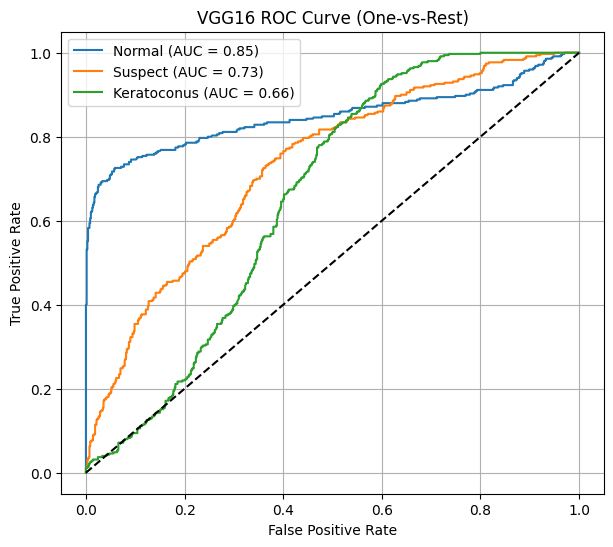

In [28]:
# Binarize labels
y_true_bin = label_binarize(y_true, classes=[0,1,2])

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
plt.figure(figsize=(7,6))

for i in range(NUM_CLASSES):
    plt.plot(fpr[i], tpr[i],
             label=f"{CLASSES[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("VGG16 ROC Curve (One-vs-Rest)")
plt.legend()
plt.grid()
plt.show()
